# Stage 2 – Customer Value Segmentation

Splits customers into value segments with K-Means on **tenure** and **MonthlyCharges** (standardised). The scaler and K-Means are fitted on the **training set only**; test customers are assigned to the nearest segment.

**Rule for k (set before running):** among k = 2–6, choose the highest silhouette score where every training segment has at least 100 churners (`config.MIN_CHURNERS_PER_SEGMENT`). The best k without this rule is kept as a robustness check for Stage 4.

## Step 1 – Load the training and test sets from Stage 1

In [1]:
# Cell 1 - Setup and data
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

ROOT = Path.cwd()
if ROOT.name in ("src", "notebooks"):
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

import config as C
from src import features as F

train = pd.read_csv(C.PROCESSED_DIR / "train.csv")
test = pd.read_csv(C.PROCESSED_DIR / "test.csv")
SEG_FEATURES = C.SEGMENT_FEATURES

# Same chart style as the EDA notebook
GREY = "#8a8984"
SEG_COLOURS = ["#2a78d6", "#1baf7a", "#4a3aa7", "#eda100"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#2b2b2b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
for d in (C.FIGURES_DIR, C.TABLES_DIR, C.MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(C.FIGURES_DIR / f"{name}.png")
    print("Saved figure:", name)

print(f"Train: {len(train):,} customers ({train[C.TARGET].sum():,} churners)")
print(f"Test:  {len(test):,} customers ({test[C.TARGET].sum():,} churners)")
print("Segmentation features:", SEG_FEATURES)

Train: 5,625 customers (1,495 churners)
Test:  1,407 customers (374 churners)
Segmentation features: ['tenure', 'MonthlyCharges']


## Step 2 – Standardise the features (fitted on the training set only)

In [2]:
# Cell 2 - Standardise tenure and MonthlyCharges using training statistics only
scaler = StandardScaler().fit(train[SEG_FEATURES])
X_train = scaler.transform(train[SEG_FEATURES])
X_test = scaler.transform(test[SEG_FEATURES])

pd.DataFrame({
    "train mean (learned)": scaler.mean_,
    "train std (learned)": scaler.scale_,
    "scaled train mean": X_train.mean(axis=0),
    "scaled test mean": X_test.mean(axis=0),
}, index=SEG_FEATURES).round(3)

,train mean (learned),train std (learned),scaled train mean,scaled test mean
tenure,32.562,24.540,-0.0,-0.029
MonthlyCharges,64.999,30.106,0.0,-0.033


## Step 3 – Evaluate k = 2 to 6
Criteria: inertia (elbow), silhouette, Davies–Bouldin, Calinski–Harabasz, stability across random starts (ARI), and the number of churners in the smallest segment.

In [3]:
# Cell 3 - K-Means for each k: quality criteria, stability and segment sizes
rows = []
for k in C.K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=C.RANDOM_STATE).fit(X_train)
    labels = km.labels_
    stability = np.mean([
        adjusted_rand_score(labels, KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_train).labels_)
        for seed in range(1, 11)
    ])
    sizes = pd.Series(labels).value_counts()
    churners = train.groupby(labels)[C.TARGET].sum()
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X_train, labels),
        "davies_bouldin": davies_bouldin_score(X_train, labels),
        "calinski_harabasz": calinski_harabasz_score(X_train, labels),
        "stability_ARI": stability,
        "smallest_segment": sizes.min(),
        "smallest_churner_count": churners.min(),
    })

k_table = pd.DataFrame(rows).set_index("k")
k_table.to_csv(C.TABLES_DIR / "08_k_selection.csv")
k_table.style.format({"inertia": "{:,.0f}", "silhouette": "{:.3f}", "davies_bouldin": "{:.3f}",
                      "calinski_harabasz": "{:,.0f}", "stability_ARI": "{:.3f}"})

,inertia,silhouette,davies_bouldin,calinski_harabasz,stability_ARI,smallest_segment,smallest_churner_count
k,,,,,,,
2,"6,253",0.411,1.014,"4,494",0.996,2472,399
3,"3,693",0.446,0.820,"5,753",0.995,1691,212
4,"2,276",0.475,0.689,"7,386",1.000,905,45
5,"1,865",0.434,0.796,"7,072",0.988,836,39
6,"1,549",0.425,0.806,"7,038",0.965,756,40


## Step 4 – Apply the decision rule

In [4]:
# Cell 4 - Choose k with the pre-set rule
eligible = k_table[k_table["smallest_churner_count"] >= C.MIN_CHURNERS_PER_SEGMENT]
K_FINAL = int(eligible["silhouette"].idxmax())
K_BEST_UNCONSTRAINED = int(k_table["silhouette"].idxmax())

print(f"k meeting the minimum of {C.MIN_CHURNERS_PER_SEGMENT} churners per segment: {eligible.index.tolist()}")
print(f"Chosen k (best silhouette among those): {K_FINAL}   silhouette = {k_table.loc[K_FINAL, 'silhouette']:.3f}")
print(f"Statistically best k (no constraint):   {K_BEST_UNCONSTRAINED}   silhouette = "
      f"{k_table.loc[K_BEST_UNCONSTRAINED, 'silhouette']:.3f}   "
      f"smallest churner count = {k_table.loc[K_BEST_UNCONSTRAINED, 'smallest_churner_count']}")
print(f"Matches config.N_SEGMENTS ({C.N_SEGMENTS})? {K_FINAL == C.N_SEGMENTS}   "
      f"Matches config.ROBUSTNESS_K ({C.ROBUSTNESS_K})? {K_BEST_UNCONSTRAINED == C.ROBUSTNESS_K}")

k meeting the minimum of 100 churners per segment: [2, 3]
Chosen k (best silhouette among those): 3   silhouette = 0.446
Statistically best k (no constraint):   4   silhouette = 0.475   smallest churner count = 45
Matches config.N_SEGMENTS (3)? True   Matches config.ROBUSTNESS_K (4)? True


Saved figure: 07_choosing_k


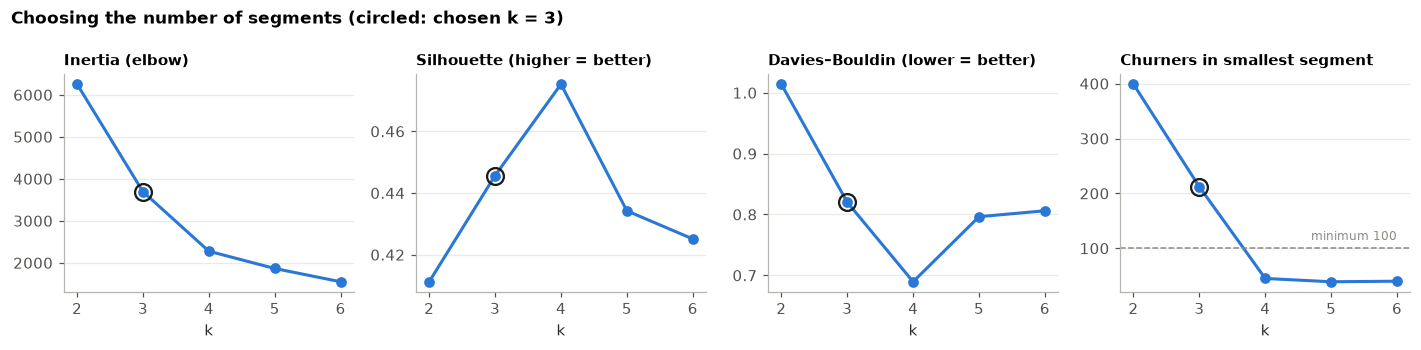

In [5]:
# Cell 5 - Figure 07: choosing k
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
panels = [("inertia", "Inertia (elbow)"), ("silhouette", "Silhouette (higher = better)"),
          ("davies_bouldin", "Davies–Bouldin (lower = better)"),
          ("smallest_churner_count", "Churners in smallest segment")]
for ax, (col, title) in zip(axes, panels):
    ax.plot(k_table.index, k_table[col], color=SEG_COLOURS[0], lw=2, marker="o", ms=6)
    ax.plot(K_FINAL, k_table.loc[K_FINAL, col], "o", ms=11, mfc="none", mec="#1b1b1b", mew=1.5)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks(list(C.K_RANGE))
    ax.set_xlabel("k")
    ax.grid(axis="x", visible=False)
axes[3].axhline(C.MIN_CHURNERS_PER_SEGMENT, color=GREY, ls="--", lw=1)
axes[3].text(6, C.MIN_CHURNERS_PER_SEGMENT + 15, f"minimum {C.MIN_CHURNERS_PER_SEGMENT}",
             color=GREY, fontsize=8, ha="right")
fig.suptitle(f"Choosing the number of segments (circled: chosen k = {K_FINAL})", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout()
save(fig, "07_choosing_k")
plt.show()

## Step 5 – Fit the final model and assign the test customers
Test customers are assigned with `predict` (no refitting). Segments are named from their centres: high- or low-value by monthly charge, new or established by tenure.

In [6]:
# Cell 6 - Final segmentation, segment names and test assignment
def fit_segments(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=C.RANDOM_STATE).fit(X_train)
    centres = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=SEG_FEATURES)
    centres["tier"] = np.where(centres["MonthlyCharges"] > train["MonthlyCharges"].median(),
                               "High-value", "Low-value")
    names = {}
    for tier, group in centres.groupby("tier"):
        group = group.sort_values("tenure")
        for position, idx in enumerate(group.index):
            if len(group) == 1:
                names[idx] = tier
            else:
                names[idx] = ("New " if position == 0 else "Established ") + tier.lower()
    centres["segment"] = centres.index.map(names)
    return km, names, centres

kmeans, SEG_NAMES, centres = fit_segments(K_FINAL)
train["segment"] = pd.Series(kmeans.labels_).map(SEG_NAMES).values
test["segment"] = pd.Series(kmeans.predict(X_test)).map(SEG_NAMES).values

ORDER = centres.sort_values(["MonthlyCharges", "tenure"])["segment"].tolist()   # low → high value
COLOUR = dict(zip(ORDER, SEG_COLOURS))

centres.set_index("segment").loc[ORDER, SEG_FEATURES].round(1).rename(
    columns={"tenure": "centre: tenure (months)", "MonthlyCharges": "centre: monthly charge"})

,centre: tenure (months),centre: monthly charge
segment,,
Low-value,29.3,26.5
New high-value,13.0,75.3
Established high-value,58.4,89.0


## Step 6 – Segment profiles
Size, tenure, value, contract mix, churn rate and share of lost revenue per segment. Customer value = 12 × MonthlyCharges.

In [7]:
# Cell 7 - Profile each segment (training set)
def profile(df):
    churn = df[C.TARGET] == 1
    lost = df.loc[churn, "MonthlyCharges"].sum()
    g = df.groupby("segment")
    out = pd.DataFrame({
        "customers": g.size(),
        "pct_customers": g.size() / len(df),
        "avg_tenure": g["tenure"].mean(),
        "avg_monthly_charge": g["MonthlyCharges"].mean(),
        "avg_value_12m": g["MonthlyCharges"].mean() * C.VALUE_HORIZON_MONTHS,
        "pct_month_to_month": g["Contract"].apply(lambda s: (s == "Month-to-month").mean()),
        "churners": g[C.TARGET].sum(),
        "churn_rate": g[C.TARGET].mean(),
        "pct_of_churners": g[C.TARGET].sum() / churn.sum(),
        "pct_of_lost_revenue": df[churn].groupby("segment")["MonthlyCharges"].sum() / lost,
    })
    return out.loc[[s for s in ORDER if s in out.index]]

seg_profile = profile(train)
seg_profile.to_csv(C.TABLES_DIR / "09_segment_profiles.csv")
pct = ["pct_customers", "pct_month_to_month", "churn_rate", "pct_of_churners", "pct_of_lost_revenue"]
seg_profile.style.format({**{c: "{:.1%}" for c in pct}, "avg_tenure": "{:.1f}",
                          "avg_monthly_charge": "{:.2f}", "avg_value_12m": "{:,.0f}"})

,customers,pct_customers,avg_tenure,avg_monthly_charge,avg_value_12m,pct_month_to_month,churners,churn_rate,pct_of_churners,pct_of_lost_revenue
segment,,,,,,,,,,
Low-value,1691,30.1%,29.3,26.41,317,43.8%,212,12.5%,14.2%,5.6%
New high-value,2120,37.7%,13.0,75.21,902,87.9%,1002,47.3%,67.0%,70.4%
Established high-value,1814,32.2%,58.4,89.04,"1,068",26.5%,281,15.5%,18.8%,24.0%


Saved figure: 08_segment_map


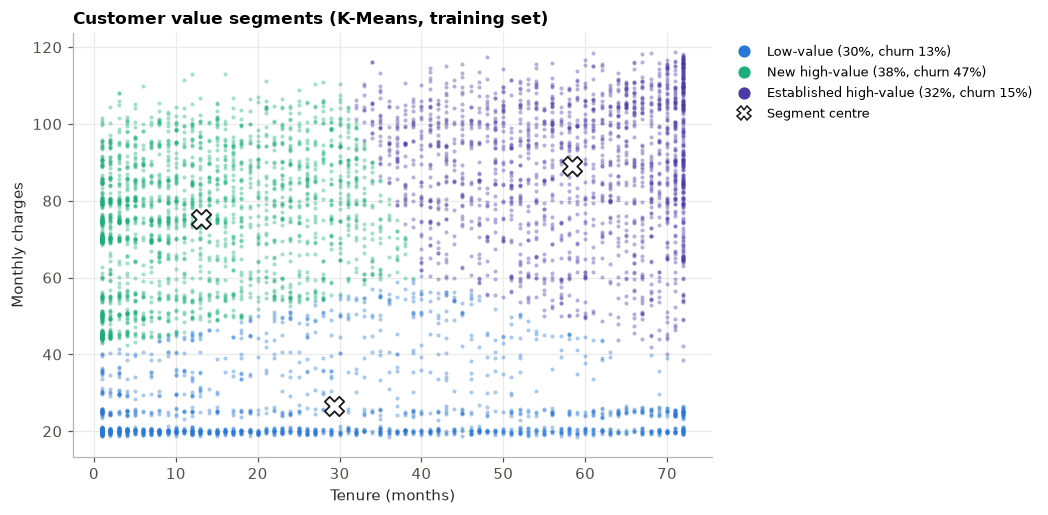

In [8]:
# Cell 8 - Figure 08: segment map (training set)
fig, ax = plt.subplots(figsize=(7.5, 5))
from matplotlib.lines import Line2D
handles = []
for seg in ORDER:
    d = train[train["segment"] == seg]
    ax.scatter(d["tenure"], d["MonthlyCharges"], s=7, alpha=0.4, lw=0, color=COLOUR[seg])
    handles.append(Line2D([], [], marker="o", ls="", ms=7, color=COLOUR[seg],
                          label=f"{seg} ({len(d) / len(train):.0%}, churn {d[C.TARGET].mean():.0%})"))
c = centres.set_index("segment")
ax.scatter(c["tenure"], c["MonthlyCharges"], marker="X", s=160, color="white", edgecolor="#1b1b1b", lw=1.2, zorder=3)
handles.append(Line2D([], [], marker="X", ls="", ms=9, mfc="white", mec="#1b1b1b", label="Segment centre"))
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Monthly charges")
ax.set_title("Customer value segments (K-Means, training set)", loc="left")
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5)
save(fig, "08_segment_map")
plt.show()

Saved figure: 09_segment_lost_revenue


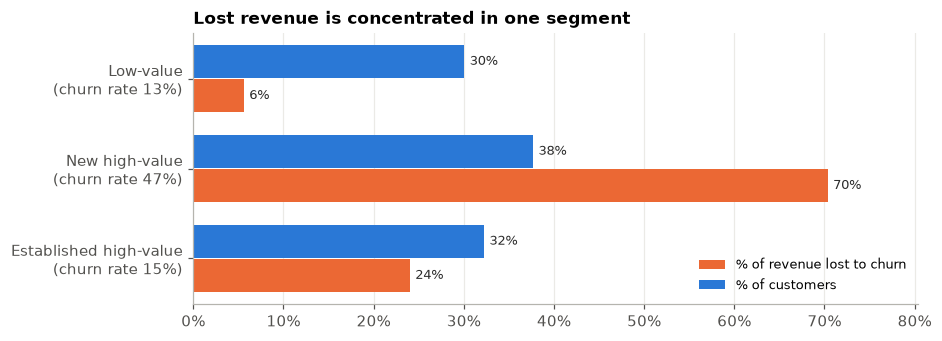

In [9]:
# Cell 9 - Figure 09: share of customers vs share of lost revenue, by segment
d = seg_profile.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.barh(y + 0.19, d["pct_customers"], height=0.36, color="#2a78d6", label="% of customers")
ax.barh(y - 0.19, d["pct_of_lost_revenue"], height=0.36, color="#eb6834", label="% of revenue lost to churn")
for yi, (pc, pl) in enumerate(zip(d["pct_customers"], d["pct_of_lost_revenue"])):
    ax.text(pc + 0.006, yi + 0.19, f"{pc:.0%}", va="center", fontsize=8.5, color="#2b2b2b")
    ax.text(pl + 0.006, yi - 0.19, f"{pl:.0%}", va="center", fontsize=8.5, color="#2b2b2b")
ax.set_yticks(y, [f"{s}\n(churn rate {r:.0%})" for s, r in zip(d.index, d["churn_rate"])])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlim(0, max(d["pct_of_lost_revenue"].max(), d["pct_customers"].max()) + 0.1)
ax.grid(axis="y", visible=False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right", fontsize=8.5)
ax.set_title("Lost revenue is concentrated in one segment", loc="left")
save(fig, "09_segment_lost_revenue")
plt.show()

## Step 7 – Do the segments generalise? (train vs test)

In [10]:
# Cell 10 - Train vs test comparison
test_profile = profile(test)
generalisation = pd.DataFrame({
    "share_train": seg_profile["pct_customers"],
    "share_test": test_profile["pct_customers"],
    "churn_rate_train": seg_profile["churn_rate"],
    "churn_rate_test": test_profile["churn_rate"],
    "churners_test": test_profile["churners"],
})
generalisation["share_diff_pts"] = (generalisation["share_test"] - generalisation["share_train"]) * 100
generalisation["churn_diff_pts"] = (generalisation["churn_rate_test"] - generalisation["churn_rate_train"]) * 100
generalisation.to_csv(C.TABLES_DIR / "10_segments_train_vs_test.csv")
generalisation.style.format({"share_train": "{:.1%}", "share_test": "{:.1%}", "churn_rate_train": "{:.1%}",
                             "churn_rate_test": "{:.1%}", "share_diff_pts": "{:+.1f}", "churn_diff_pts": "{:+.1f}"})

,share_train,share_test,churn_rate_train,churn_rate_test,churners_test,share_diff_pts,churn_diff_pts
segment,,,,,,,
Low-value,30.1%,31.7%,12.5%,12.1%,54,+1.6,-0.4
New high-value,37.7%,37.2%,47.3%,48.4%,253,-0.5,+1.1
Established high-value,32.2%,31.1%,15.5%,15.3%,67,-1.1,-0.2


## Step 8 – Is churn related to customer value?
Verbeke et al. (2012) assumed one value for all customers; this step checks whether churn and value are related.

In [11]:
# Cell 11 - Churn vs value, at customer and segment level (training set)
from scipy.stats import pointbiserialr, spearmanr

r, p = pointbiserialr(train[C.TARGET], train["MonthlyCharges"])
rho, p_rho = spearmanr(seg_profile["avg_monthly_charge"], seg_profile["churn_rate"])
high = train["segment"].str.contains("high-value", case=False)

print(f"Customer level: correlation between churn and monthly charge  r = {r:.3f} (p = {p:.1e})")
print(f"Churn rate, high-value segments: {train.loc[high, C.TARGET].mean():.1%}   "
      f"low-value segments: {train.loc[~high, C.TARGET].mean():.1%}")
print(f"Revenue lost from high-value segments: "
      f"{train.loc[high & (train[C.TARGET] == 1), 'MonthlyCharges'].sum() / train.loc[train[C.TARGET] == 1, 'MonthlyCharges'].sum():.1%}")
seg_profile[["avg_value_12m", "churn_rate", "pct_of_lost_revenue"]].style.format(
    {"avg_value_12m": "{:,.0f}", "churn_rate": "{:.1%}", "pct_of_lost_revenue": "{:.1%}"})

Customer level: correlation between churn and monthly charge  r = 0.193 (p = 1.5e-48)
Churn rate, high-value segments: 32.6%   low-value segments: 12.5%
Revenue lost from high-value segments: 94.4%


,avg_value_12m,churn_rate,pct_of_lost_revenue
segment,,,
Low-value,317,12.5%,5.6%
New high-value,902,47.3%,70.4%
Established high-value,"1,068",15.5%,24.0%


## Step 9 – Comparison with the EDA median split and with Ali et al. (2026)

In [12]:
# Cell 12 - Agreement with the EDA median split, and comparison with Ali et al. (2026)
median_split = pd.Series(np.where(train["tenure"] <= train["tenure"].median(), "New", "Long-standing"), index=train.index,
                         name="EDA median split") + ", " + np.where(train["MonthlyCharges"] > train["MonthlyCharges"].median(),
                                                                    "high-paying", "low-paying")
print(f"ARI between K-Means segments and the EDA median split: "
      f"{adjusted_rand_score(train['segment'], median_split):.3f}")
display(pd.crosstab(train["segment"], median_split, margins=True).loc[ORDER + ["All"]])

comparison = pd.DataFrame({
    "This thesis": [f"{K_FINAL}", "tenure, MonthlyCharges", "Training set only",
                    "Silhouette + DB + CH + stability + min. churners",
                    " / ".join(f"{s}: {r:.0%}" for s, r in seg_profile["churn_rate"].items())],
    "Ali et al. (2026)": ["3", "tenure, MonthlyCharges, TotalCharges + 4 service flags", "All data (not stated)",
                          "Elbow only", "Low: 11.2% / Medium: 51.7% / High: 18.0%"],
}, index=["k", "Features", "Fitted on", "How k was chosen", "Churn rate by segment"])
comparison

ARI between K-Means segments and the EDA median split: 0.445


EDA median split,"Long-standing, high-paying","Long-standing, low-paying","New, high-paying","New, low-paying",All
segment,,,,,
Low-value,0,759,0,932,1691
New high-value,153,60,1161,746,2120
Established high-value,1496,318,0,0,1814
All,1649,1137,1161,1678,5625


,This thesis,Ali et al. (2026)
k,3,3
Features,"tenure, MonthlyCharges","tenure, MonthlyCharges, TotalCharges + 4 servi..."
Fitted on,Training set only,All data (not stated)
How k was chosen,Silhouette + DB + CH + stability + min. churners,Elbow only
Churn rate by segment,Low-value: 13% / New high-value: 47% / Establi...,Low: 11.2% / Medium: 51.7% / High: 18.0%


## Step 10 – Save the segmentation
Saves the scaler, K-Means model and segment names (k = 3, and k = 4 for the robustness check) so later stages use `src/features.py → assign_segment()`.

In [13]:
# Cell 13 - Save models and segmented data; check assign_segment() reproduces the notebook
def save_model(k, km, names):
    path = C.MODELS_DIR / f"segmentation_k{k}.joblib"
    joblib.dump({"scaler": scaler, "kmeans": km, "names": names, "features": SEG_FEATURES,
                 "fitted_on": "training set only", "random_state": C.RANDOM_STATE}, path)
    return path

print("Saved:", save_model(K_FINAL, kmeans, SEG_NAMES).name)
km_robust, names_robust, _ = fit_segments(C.ROBUSTNESS_K)
print("Saved:", save_model(C.ROBUSTNESS_K, km_robust, names_robust).name, "(robustness check)")

train["segment_k4"] = pd.Series(km_robust.labels_).map(names_robust).values
test["segment_k4"] = pd.Series(km_robust.predict(X_test)).map(names_robust).values
train.to_csv(C.PROCESSED_DIR / "train_segmented.csv", index=False)
test.to_csv(C.PROCESSED_DIR / "test_segmented.csv", index=False)
print("Saved: train_segmented.csv, test_segmented.csv")

import importlib
importlib.reload(F)
print("assign_segment() reproduces train segments:", (F.assign_segment(train) == train["segment"]).all())
print("assign_segment() reproduces test segments: ", (F.assign_segment(test) == test["segment"]).all())
print("\nk = 4 segments (robustness check), training set:")
print(train.groupby("segment_k4")[C.TARGET].agg(customers="size", churners="sum", churn_rate="mean").round(3))

Saved: segmentation_k3.joblib
Saved: segmentation_k4.joblib (robustness check)
Saved: train_segmented.csv, test_segmented.csv
assign_segment() reproduces train segments: True
assign_segment() reproduces test segments:  True

k = 4 segments (robustness check), training set:
                        customers  churners  churn_rate
segment_k4                                             
Established high-value       1575       253       0.161
Established low-value         905        45       0.050
New high-value               1754       854       0.487
New low-value                1391       343       0.247


## Stage 2 findings
**1. The rule selects k = 3** (silhouette 0.446). k = 4 has the best silhouette (0.475) but its smallest segment has only 45 training churners. All solutions are stable (ARI ≥ 0.97; 0.995 for k = 3).

**2. Three value segments (training set):**

| Segment | Customers | Avg tenure | Avg monthly charge | 12-month value | Month-to-month | Churn rate | Share of lost revenue |
|---|---|---|---|---|---|---|---|
| Low-value | 30% | 29 months | 26 | 317 | 44% | 12.5% | 6% |
| New high-value | 38% | 13 months | 75 | 902 | 88% | **47.3%** | **70%** |
| Established high-value | 32% | 58 months | 89 | 1,068 | 27% | 15.5% | 24% |

**3. The segments generalise:** on the test set, segment sizes differ by ≤ 1.6 points and churn rates by ≤ 1.1 points.

**4. Churn and value are linked:** the two high-value segments cause 94% of lost revenue, and new high-value customers churn at 47% vs 16% for established ones.

**5. Comparison:** only moderate agreement with the EDA median split (ARI = 0.45); same three-tier structure as Ali et al. (2026).

Churners per segment: 212 / 1,002 / 281 (train), 54 / 253 / 67 (test).

**Outputs:** Tables 08–10; Figures 07–09; `segmentation_k3.joblib`, `segmentation_k4.joblib`.